In [7]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix

In [9]:
path = "C:/Users/Mega Pc/Desktop/Kraya/M1-FIND/S1/IA/base_finance_supervisee.csv"
df = pd.read_csv(path)
df.head()

,age,revenu_annuel,montant_credit,taux_interet,duree_credit,ratio_endettement,score_credit,type_contrat,defaut
0,59.0,24572.13,35483.42,5.91,215.0,1.444,NaN,CDD,1
1,49.0,26867.38,27705.82,NaN,212.0,1.031,585.0,CDI,0
2,35.0,49431.53,31753.12,5.46,202.0,0.642,727.0,CDD,0
3,63.0,34639.43,9425.81,2.19,315.0,0.272,423.0,Retraité,0
4,28.0,65356.01,40274.23,3.44,243.0,0.616,NaN,CDD,0


In [11]:
print(df)
print("\n✅ Données chargées avec succès !")
print("Shape :", df.shape)
display(df.head())
if 'id' in df.columns:
    df = df.drop(columns=['id'])
print(df.shape)
print("\n=== INFO ===")
print(df.info())
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())

       age  revenu_annuel  montant_credit  taux_interet  duree_credit  \
0     59.0       24572.13        35483.42          5.91         215.0   
1     49.0       26867.38        27705.82           NaN         212.0   
2     35.0       49431.53        31753.12          5.46         202.0   
3     63.0       34639.43         9425.81          2.19         315.0   
4     28.0       65356.01        40274.23          3.44         243.0   
...    ...            ...             ...           ...           ...   
9995  53.0       47753.73        12569.85          1.16         216.0   
9996  21.0       39915.67        19808.13           NaN         347.0   
9997  33.0       45789.61        15785.52          5.67         137.0   
9998  57.0       41185.95        24219.27          6.71         359.0   
9999  40.0       50538.69        19168.51          4.47          83.0   

      ratio_endettement  score_credit type_contrat  defaut  
0                 1.444           NaN          CDD       1  
1

,age,revenu_annuel,montant_credit,taux_interet,duree_credit,ratio_endettement,score_credit,type_contrat,defaut
0,59.0,24572.13,35483.42,5.91,215.0,1.444,NaN,CDD,1
1,49.0,26867.38,27705.82,NaN,212.0,1.031,585.0,CDI,0
2,35.0,49431.53,31753.12,5.46,202.0,0.642,727.0,CDD,0
3,63.0,34639.43,9425.81,2.19,315.0,0.272,423.0,Retraité,0
4,28.0,65356.01,40274.23,3.44,243.0,0.616,NaN,CDD,0


(10000, 9)

=== INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                9267 non-null   float64
 1   revenu_annuel      9284 non-null   float64
 2   montant_credit     9274 non-null   float64
 3   taux_interet       9298 non-null   float64
 4   duree_credit       9281 non-null   float64
 5   ratio_endettement  9344 non-null   float64
 6   score_credit       9360 non-null   float64
 7   type_contrat       9290 non-null   object 
 8   defaut             10000 non-null  int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 703.3+ KB
None

Valeurs manquantes par colonne :
age                  733
revenu_annuel        716
montant_credit       726
taux_interet         702
duree_credit         719
ratio_endettement    656
score_credit         640
type_contrat         710
defaut                 0
dtype: int64

In [11]:
X = df.drop("defaut", axis=1)
y = df["defaut"]

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("\nVariables quantitatives :", num_cols)
print("Variables qualitatives  :", cat_cols)


# ==============================
# 3. PIPELINES DE PRÉTRAITEMENT
# ==============================

numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),          # remplacer NaN
    ("scaler", StandardScaler())                          # normalisation
])

categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")), # remplacer NaN
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))  # encodage
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, num_cols),
        ("cat", categorical_pipe, cat_cols),
    ]
)


# ==============================
# 4. TRAIN / TEST SPLIT
# ==============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)


Variables quantitatives : ['age', 'revenu_annuel', 'montant_credit', 'taux_interet', 'duree_credit', 'ratio_endettement', 'score_credit']
Variables qualitatives  : ['type_contrat']


In [12]:
log_model = Pipeline(steps=[
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Modèle 2 : KNN
knn_model = Pipeline(steps=[
    ("prep", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])


# ==============================
# 6. ENTRAÎNEMENT
# ==============================
log_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'revenu_annuel',
                                                   'montant_credit',
                                                   'taux_interet',
                                                   'duree_credit',
                                                   'ratio_endettement',
                                                   'score_credit']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['type_contrat'])])),
                ('model', KNeighborsClassifier())])

In [13]:
pred_log = log_model.predict(X_test)
pred_knn = knn_model.predict(X_test)

In [14]:
def eval_model(name,  y_test, y_pred):
    acc = accuracy_score( y_test, y_pred)
    rec = recall_score( y_test, y_pred, pos_label=1)
    f1 = f1_score( y_test, y_pred, pos_label=1)
    return pd.Series({'Accuracy': acc, 'Recall_defaut': rec, 'F1_defaut': f1}, name=name)

results = pd.DataFrame([
    eval_model('Régression Logistique', y_test, pred_log),
    eval_model('KNN (k=7)', y_test, pred_knn)
])
results

,Accuracy,Recall_defaut,F1_defaut
Régression Logistique,0.7668,0.550000,0.629371
KNN (k=7),0.7196,0.524444,0.573860


In [15]:
from sklearn.tree import DecisionTreeClassifier

In [16]:
tree_model = Pipeline(steps=[
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

pred_tree = tree_model.predict(X_test)

In [17]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ("prep", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

pred_rf = rf_model.predict(X_test)

In [18]:
results = pd.DataFrame([
    eval_model('Régression Logistique', y_test, pred_log),
    eval_model('KNN', y_test, pred_knn),
    eval_model('Decision Tree', y_test, pred_tree),
    eval_model('Random Forest', y_test, pred_rf)
])

results

,Accuracy,Recall_defaut,F1_defaut
Régression Logistique,0.7668,0.550000,0.629371
KNN,0.7196,0.524444,0.573860
Decision Tree,0.7580,0.464444,0.580153
Random Forest,0.7596,0.546667,0.620820


In [19]:
results.sort_values(
    by="F1_defaut",
    ascending=False
)

,Accuracy,Recall_defaut,F1_defaut
Régression Logistique,0.7668,0.550000,0.629371
Random Forest,0.7596,0.546667,0.620820
Decision Tree,0.7580,0.464444,0.580153
KNN,0.7196,0.524444,0.573860


In [20]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred_rf)

print(cm)


[[1407  193]
 [ 408  492]]


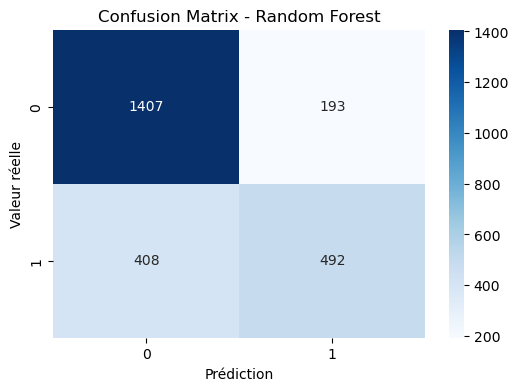

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Prédiction")
plt.ylabel("Valeur réelle")
plt.title("Confusion Matrix - Random Forest")

plt.show()

In [22]:
rf = rf_model.named_steps["model"]

In [23]:
feature_names = rf_model.named_steps[
    "prep"
].get_feature_names_out()

In [24]:
importance = pd.DataFrame({
    "Variable": feature_names,
    "Importance": rf.feature_importances_
})

In [25]:
importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance.head(10)

,Variable,Importance
5,num__ratio_endettement,0.264784
1,num__revenu_annuel,0.172776
2,num__montant_credit,0.155449
6,num__score_credit,0.102387
3,num__taux_interet,0.097478
4,num__duree_credit,0.093392
0,num__age,0.079290
7,cat__type_contrat_CDI,0.011655
8,cat__type_contrat_Indépendant,0.008600
10,cat__type_contrat_Sans emploi,0.007916


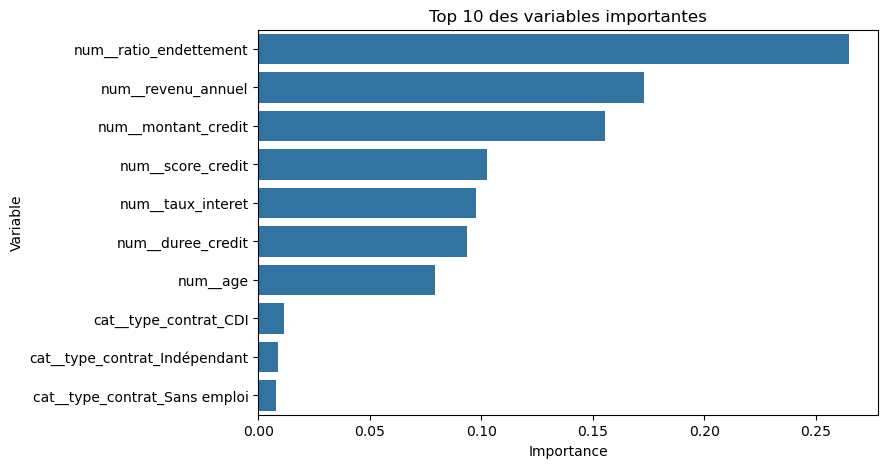

In [26]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Variable"
)

plt.title("Top 10 des variables importantes")

plt.show()

In [28]:
proba_rf = rf_model.predict_proba(X_test)
pd_default = proba_rf[:,1]

In [29]:
results_clients = X_test.copy()

results_clients["Actual_Default"] = y_test.values

results_clients["Predicted_Default"] = pred_rf

results_clients["Probability_Default"] = pd_default

results_clients.head()

,age,revenu_annuel,montant_credit,taux_interet,duree_credit,ratio_endettement,score_credit,type_contrat,Actual_Default,Predicted_Default,Probability_Default
8839,NaN,19968.20,24480.07,3.08,359.0,1.226,500.0,Indépendant,1,1,0.95
8007,43.0,21219.50,12620.51,5.62,40.0,NaN,698.0,Indépendant,0,1,0.54
7564,32.0,10335.95,9460.12,5.85,312.0,0.915,631.0,NaN,1,1,0.67
6593,53.0,46581.60,5279.20,4.63,138.0,0.113,NaN,NaN,0,0,0.02
3381,56.0,60421.49,3216.10,5.98,350.0,0.053,588.0,CDI,0,0,0.09


In [30]:
results_clients.sort_values(
    "Probability_Default",
    ascending=False
).head(20)

,age,revenu_annuel,montant_credit,taux_interet,duree_credit,ratio_endettement,score_credit,type_contrat,Actual_Default,Predicted_Default,Probability_Default
9742,45.0,19276.26,40741.40,4.06,199.0,2.114,574.0,CDD,1,1,1.00
9872,56.0,7609.50,36931.43,3.38,95.0,4.853,722.0,CDI,1,1,1.00
3383,37.0,5000.00,33386.53,3.08,120.0,5.000,559.0,CDI,1,1,1.00
4718,65.0,15330.94,33488.63,4.64,236.0,2.184,605.0,NaN,1,1,1.00
6502,38.0,13204.20,40087.91,NaN,237.0,3.036,602.0,CDD,1,1,1.00
1705,68.0,12861.62,22245.66,5.63,353.0,1.730,612.0,CDI,1,1,1.00
1329,52.0,10679.79,40186.19,5.03,NaN,3.763,450.0,Retraité,1,1,1.00
4799,26.0,5189.48,13518.37,4.03,312.0,2.605,582.0,CDI,1,1,1.00
5632,58.0,5000.00,33944.16,4.69,348.0,5.000,618.0,CDI,1,1,1.00
662,56.0,8622.15,27991.79,4.48,156.0,3.246,565.0,Retraité,1,1,1.00


In [31]:
results_clients.to_csv(
    "credit_risk_results.csv",
    index=False
)

In [32]:
importance.to_csv(
    "feature_importance.csv",
    index=False
)

In [33]:
import os

os.listdir()

[' logistic_regression_correction.ipynb',
 '.ipynb_checkpoints',
 '577791828_1572638310751353_6644011284727553962_n.jpg',
 'appart.csv',
 'base_defaillance_clients.csv',
 'base_economique_300lignes.xlsx',
 'base_finance_digitale.csv',
 'base_finance_supervisee.csv',
 'base_logit_gestion_turnover.csv',
 'base_logit_gestion_turnoverr.csv',
 'base_regression_gestionn.csv',
 'Copie_de_comparaison_logit_knn_etudiants.ipynb',
 'Copie_de_notebook_knn_defaillance_clients_etudiants.ipynb',
 'correction_serie_révision.pdf',
 'credit_risk_results.csv',
 'Depot_notebook_logit_gestion_turnover_etudiants.ipynb',
 'etudiants.csv',
 'etudiants.xlsx',
 'feature_importance.csv',
 'finance_4vars_100.csv',
 'finance_simple.csv',
 'fintech_credit.csv',
 'KNN.ipynb',
 'linear.xlsx',
 'Linear_regression_correction.ipynb',
 'Linear_regression_ESB – Copie (5).pdf',
 'logistic regression (3).pdf',
 'notebook_regression_knn_comparison_etudiant.ipynb',
 'Notebook_regression_logistique_finance_digitale_etudiant--.

In [34]:
results_clients["Risk_Level"] = pd.cut(
    results_clients["Probability_Default"],
    bins=[0, 0.3, 0.7, 1],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

results_clients["Risk_Level"].value_counts()

Risk_Level
Low Risk       1248
Medium Risk     859
High Risk       383
Name: count, dtype: int64

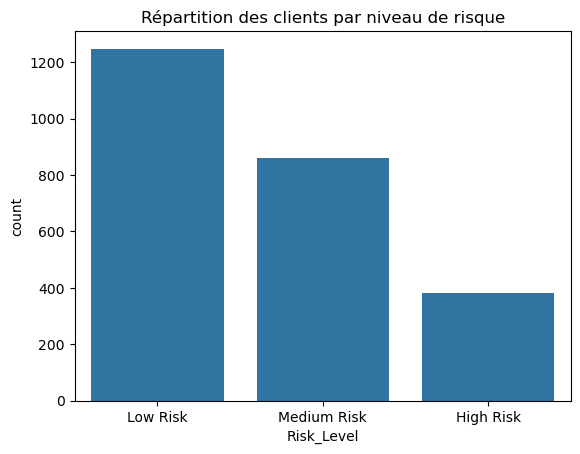

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(
    x="Risk_Level",
    data=results_clients,
    order=["Low Risk","Medium Risk","High Risk"]
)

plt.title("Répartition des clients par niveau de risque")

plt.show()

C:\Users\Mega Pc\AppData\Local\Temp\ipykernel_18468\148625096.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results_clients.groupby("Risk_Level")[


             revenu_annuel  montant_credit  ratio_endettement  score_credit
Risk_Level                                                                 
Low Risk      47109.442075    14945.676883           0.326534    612.193860
Medium Risk   37249.417102    24054.950692           0.651545    586.366544
High Risk     21355.115627    28587.486903           1.592182    593.638889
Risk_Level     Low Risk  Medium Risk  High Risk
type_contrat                                   
CDD           47.203579    36.912752  15.883669
CDI           53.809524    32.476190  13.714286
Indépendant   46.892655    34.180791  18.926554
Retraité      45.714286    32.380952  21.904762
Sans emploi   39.840637    46.613546  13.545817


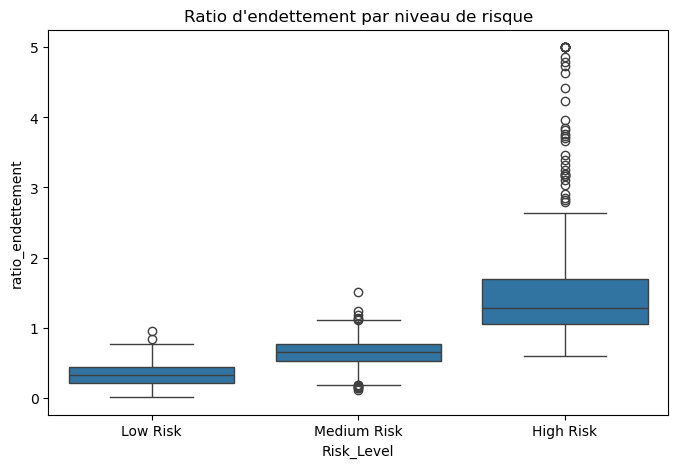

              precision    recall  f1-score   support

           0       0.78      0.88      0.82      1600
           1       0.72      0.55      0.62       900

    accuracy                           0.76      2500
   macro avg       0.75      0.71      0.72      2500
weighted avg       0.75      0.76      0.75      2500



In [42]:
# Moyennes des variables par niveau de risque
print(
    results_clients.groupby("Risk_Level")[
        [
            "revenu_annuel",
            "montant_credit",
            "ratio_endettement",
            "score_credit"
        ]
    ].mean()
)

# Répartition des niveaux de risque par type de contrat
print(
    pd.crosstab(
        results_clients["type_contrat"],
        results_clients["Risk_Level"],
        normalize="index"
    ) * 100
)

# Visualisation du ratio d'endettement
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.boxplot(
    data=results_clients,
    x="Risk_Level",
    y="ratio_endettement"
)

plt.title("Ratio d'endettement par niveau de risque")
plt.show()

# Rapport de classification
from sklearn.metrics import classification_report

print(classification_report(y_test, pred_rf))

In [43]:
from sklearn.metrics import classification_report

print(classification_report(y_test, pred_rf))

              precision    recall  f1-score   support

           0       0.78      0.88      0.82      1600
           1       0.72      0.55      0.62       900

    accuracy                           0.76      2500
   macro avg       0.75      0.71      0.72      2500
weighted avg       0.75      0.76      0.75      2500



In [44]:
results_clients["Risk_Level"] = pd.cut(
    results_clients["Probability_Default"],
    bins=[0, 0.3, 0.7, 1],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

In [45]:
results_clients.head()

,age,revenu_annuel,montant_credit,taux_interet,duree_credit,ratio_endettement,score_credit,type_contrat,Actual_Default,Predicted_Default,Probability_Default,Risk_Level
8839,NaN,19968.20,24480.07,3.08,359.0,1.226,500.0,Indépendant,1,1,0.95,High Risk
8007,43.0,21219.50,12620.51,5.62,40.0,NaN,698.0,Indépendant,0,1,0.54,Medium Risk
7564,32.0,10335.95,9460.12,5.85,312.0,0.915,631.0,NaN,1,1,0.67,Medium Risk
6593,53.0,46581.60,5279.20,4.63,138.0,0.113,NaN,NaN,0,0,0.02,Low Risk
3381,56.0,60421.49,3216.10,5.98,350.0,0.053,588.0,CDI,0,0,0.09,Low Risk


In [46]:
results_clients.to_csv(
    "credit_risk_results.csv",
    index=False
)

In [48]:
results_clients = results_clients.reset_index(drop=True)

results_clients["Client_ID"] = range(
    1,
    len(results_clients) + 1
)

In [49]:
results_clients.to_csv(
    "credit_risk_results.csv",
    index=False
)

In [50]:
results_clients = results_clients.reset_index(drop=True)

results_clients["Client_ID"] = range(
    1,
    len(results_clients) + 1
)

results_clients.to_csv(
    "credit_risk_results.csv",
    index=False
)

In [51]:
results_clients.columns

Index(['age', 'revenu_annuel', 'montant_credit', 'taux_interet',
       'duree_credit', 'ratio_endettement', 'score_credit', 'type_contrat',
       'Actual_Default', 'Predicted_Default', 'Probability_Default',
       'Risk_Level', 'Client_ID'],
      dtype='object')

In [52]:
results_clients.head()

,age,revenu_annuel,montant_credit,taux_interet,duree_credit,ratio_endettement,score_credit,type_contrat,Actual_Default,Predicted_Default,Probability_Default,Risk_Level,Client_ID
0,NaN,19968.20,24480.07,3.08,359.0,1.226,500.0,Indépendant,1,1,0.95,High Risk,1
1,43.0,21219.50,12620.51,5.62,40.0,NaN,698.0,Indépendant,0,1,0.54,Medium Risk,2
2,32.0,10335.95,9460.12,5.85,312.0,0.915,631.0,NaN,1,1,0.67,Medium Risk,3
3,53.0,46581.60,5279.20,4.63,138.0,0.113,NaN,NaN,0,0,0.02,Low Risk,4
4,56.0,60421.49,3216.10,5.98,350.0,0.053,588.0,CDI,0,0,0.09,Low Risk,5


In [1]:
pip install streamlit plotly pandas

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [2]:
Credit_Risk_App/

├── app.py
├── credit_risk_results.csv
└── feature_importance.csv

SyntaxError: invalid character '├' (U+251C) (2146344595.py, line 3)

In [3]:
Credit_Risk_App

NameError: name 'Credit_Risk_App' is not defined

In [4]:
import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Credit Risk Dashboard",
    page_icon="🏦",
    layout="wide"
)

st.title("🏦 Credit Risk Dashboard")

df = pd.read_csv("credit_risk_results.csv")

st.dataframe(df.head())

2026-10-12 11:16:20.480 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 11:16:20.481 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 11:16:20.870 
  command:

    streamlit run C:\Anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-12 11:16:20.871 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 11:16:20.965 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 11:16:20.967 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [5]:
import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Credit Risk Dashboard",
    page_icon="🏦",
    layout="wide"
)

st.title("🏦 Credit Risk Dashboard")

df = pd.read_csv("credit_risk_results.csv")

st.dataframe(df.head())

2026-10-12 11:16:40.692 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 11:16:40.694 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 11:16:40.695 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 11:16:40.708 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 11:16:40.709 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [6]:
import streamlit as st

st.title("🏦 Credit Risk Dashboard")

st.write("Hello Driss!")

2026-10-12 15:04:22.494 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 15:04:22.502 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 15:04:22.518 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-12 15:04:22.521 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
